# Milestone 3 – Improving ResNet-18 on BIWI (forward / away)
**Screen Privacy Through Head Orientation · DMET 901**

Milestone 2 result (ResNet-18, 4 unseen test people): **macro-F1 0.891**, accuracy 89.5%.
Two problems from Milestone 2: the model **memorises the 12 training people** (train F1 0.995 vs. validation 0.855),
and **most errors sit within 5° of the 20° line**.

We test three improvements. None of them changes the hyperparameters, the loss, the metrics or the model family, and none uses augmentation:

| # | Improvement | What changes | Why |
|---|---|---|---|
| A | **Small-input ResNet-18** | First convolution uses stride 1 and the first max-pool is removed, so the network reads the 64 × 64 crop directly instead of a blurry 224 × 224 enlargement | Keeps the fine detail of small faces |
| B | **More people: 300W-LP** | Add the 300W-LP face crops (thousands of different people, with head angles) to the training set. Images within 2.5° of the 20° line are left out because their angles are less precise | With only 12 people the network learns faces, not head direction |
| C | **Attention blocks (Squeeze-and-Excitation)** | A small SE block inside each of the 8 residual blocks of ResNet-18 | Lets the network weight the channels that describe head direction |

Each improvement is run alone, then the promising ones are combined. Every setting is run with **3 seeds** (42, 43, 44),
and we report the mean ± standard deviation, because Milestone 2 showed that one run can be lucky.

**Extra breakdown: accepted vs. real errors.** A head at 19.9° is "forward" and one at 20.1° is "away", but no camera or person can tell them apart.
Every model is trained and scored normally. Afterwards each wrong prediction is sorted into one of two groups:
- **Accepted error:** the head is between 17.5° and 22.5°, i.e. within ±2.5° of the 20° line.
- **Real error:** a clearly forward head (below 17.5°) predicted *away*, or a clearly away head (above 22.5°) predicted *forward*.

This is a breakdown of the errors, reported *next to* macro-F1 and accuracy. Those stay the main metrics and are computed exactly as in Milestone 2.

**How to run (Google Colab):** *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*.

## 1. Setup and data download
Same source as Milestones 1 and 2: the FSA-Net data archive (Google Drive) contains the BIWI crops **and** the 300W-LP crops.
We keep only the files we use. The HeadPose+ angle files come from GitHub.

In [1]:
import copy, json, re, subprocess, time, zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from torchvision.models import ResNet18_Weights, resnet18

DATA = Path("../data") if Path("../data").exists() else Path("data")
DATA.mkdir(exist_ok=True)
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
CKPT = Path("checkpoints"); CKPT.mkdir(exist_ok=True)

# 300W-LP comes in 4 parts. The archive also has "_Flip" copies (mirrored images = augmentation): we do NOT use them.
LP_PARTS = ["AFW", "HELEN", "IBUG", "LFPW"]
needed = [DATA / "BIWI_noTrack.npz"] + [DATA / f"300W_LP_{p}.npz" for p in LP_PARTS]
if not all(f.exists() for f in needed):
    zip_path = DATA / "fsanet_data.zip"                   # ~1.4 GB
    if not zip_path.exists():
        try:
            import gdown
        except ImportError:
            subprocess.run(["pip", "-q", "install", "gdown"], check=True); import gdown
        gdown.download(id="1j6GMx33DCcbUOS8J3NHZ-BMHgk7H-oC_", output=str(zip_path))
    inside_zip = {"BIWI_noTrack.npz": "data/BIWI_noTrack.npz", **{f"300W_LP_{p}.npz": f"data/type1/{p}.npz" for p in LP_PARTS}}
    with zipfile.ZipFile(zip_path) as z:
        for f in needed:
            if not f.exists():
                f.write_bytes(z.read(inside_zip[f.name]))
if not (DATA / "headposeplus").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/kuhnkeF/headposeplus", str(DATA / "headposeplus")], check=True)
for f in needed:
    print(f"{f.name:22} {f.stat().st_size / 1e6:7.1f} MB")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")

BIWI_noTrack.npz         162.8 MB
300W_LP_AFW.npz           64.1 MB
300W_LP_HELEN.npz        463.9 MB
300W_LP_IBUG.npz          22.0 MB
300W_LP_LFPW.npz         203.8 MB
PyTorch 2.14.1+cu126 | device: NVIDIA GeForce RTX 4070 Laptop GPU


## 2. Run configuration
The training settings are **identical to Milestone 2**. Only the four switches in `EXPERIMENTS` differ between runs.

In [2]:
CFG = dict(
    threshold_deg=20,            # forward if |yaw| <= 20 and |pitch| <= 20
    input_size=224,              # 64x64 crops are enlarged to 224x224 (not used by the small-input model)
    batch_size=64,
    optimizer="Adam",
    stage1_epochs=5,  stage1_lr=1e-3,    # stage 1: backbone frozen, train the new 2-class layer (+ new SE blocks)
    stage2_epochs=10, stage2_lr=1e-4,    # stage 2: also fine-tune layer4
    loss="weighted cross-entropy",       # class weights from training counts only
    augmentation="none",
    model_selection="best validation macro-F1",
    seeds=[42, 43, 44],                  # every experiment is repeated with these seeds
    grace_deg=2.5,                       # errors within 2.5 deg of the line are "accepted", all others are "real"
)
EXPERIMENTS = {                          # A = small input, B = 300W-LP, C = SE attention
    "Baseline (MS2)":  dict(small_input=False, extra_300wlp=False, se=False),
    "A: Small input":  dict(small_input=True,  extra_300wlp=False, se=False),
    "B: + 300W-LP":    dict(small_input=False, extra_300wlp=True,  se=False),
    "C: SE attention": dict(small_input=False, extra_300wlp=False, se=True),
    # Combinations, added after the single runs: A and B improved validation, C less so
    "A + B":           dict(small_input=True,  extra_300wlp=True,  se=False),
    "A + B + C":       dict(small_input=True,  extra_300wlp=True,  se=True),
}
# Same person-level split as Milestones 1 and 2 (12 / 4 / 4 people).
SEQ_TO_PERSON = {1: "F01", 2: "F02", 3: "F03", 4: "F04", 5: "F05", 6: "F06", 7: "M01", 8: "M02", 9: "M03", 10: "M04",
                 11: "M05", 12: "M06", 13: "M07", 14: "M08", 15: "F03", 16: "M09", 17: "M10", 18: "F05", 19: "M11",
                 20: "M12", 21: "F02", 22: "M01", 23: "M13", 24: "M14"}
VAL_SEQS  = [6, 9, 16, 19]
TEST_SEQS = [1, 2, 17, 20, 21]
CLASSES = ["away", "forward"]            # class 0 = away, class 1 = forward
T, G = CFG["threshold_deg"], CFG["grace_deg"]
for k, v in CFG.items():
    print(f"{k:16} {v}")
print()
for name, opts in EXPERIMENTS.items():
    print(f"{name:18} {opts}")

threshold_deg    20
input_size       224
batch_size       64
optimizer        Adam
stage1_epochs    5
stage1_lr        0.001
stage2_epochs    10
stage2_lr        0.0001
loss             weighted cross-entropy
augmentation     none
model_selection  best validation macro-F1
seeds            [42, 43, 44]
grace_deg        2.5

Baseline (MS2)     {'small_input': False, 'extra_300wlp': False, 'se': False}
A: Small input     {'small_input': True, 'extra_300wlp': False, 'se': False}
B: + 300W-LP       {'small_input': False, 'extra_300wlp': True, 'se': False}
C: SE attention    {'small_input': False, 'extra_300wlp': False, 'se': True}
A + B              {'small_input': True, 'extra_300wlp': True, 'se': False}
A + B + C          {'small_input': True, 'extra_300wlp': True, 'se': True}


## 3. Data
**BIWI** is loaded, labelled and split exactly as in Milestone 2 (the counts are checked against the Milestone 1 table).
**300W-LP** is only ever added to the *training* set. Validation and test are always the same BIWI people.

In [3]:
crops = np.load(DATA / "BIWI_noTrack.npz")
biwi_images = crops["image"][..., ::-1]                    # BGR -> RGB, (N, 64, 64, 3)
hpp = DATA / "headposeplus" / "data"
fsa, plus = np.load(hpp / "Biwi_FSA-Net.npz"), np.load(hpp / "Biwi_plus.npz")
row = {name: i for i, name in enumerate(plus["images"])}
match = np.array([row[name] for name in fsa["images"]])
biwi_pitch, biwi_yaw = plus["pyr"][match, 0], plus["pyr"][match, 1]   # calibrated angles (as in MS1/MS2)
seq = np.array([int(name[:2]) for name in fsa["images"]])
assert len(biwi_images) == len(fsa["images"]) == 13219
assert np.abs(crops["pose"] - fsa["ypr"]).max() < 1e-6

# ---- 300W-LP: crops + (yaw, pitch, roll) in degrees, from fitting a 3D face model to each photo
lp = [np.load(DATA / f"300W_LP_{p}.npz") for p in LP_PARTS]
lp_images = np.concatenate([d["image"][..., ::-1] for d in lp])      # BGR -> RGB, like BIWI
lp_pose = np.concatenate([d["pose"] for d in lp])
lp_yaw, lp_pitch = lp_pose[:, 0], lp_pose[:, 1]
lp_dist = np.maximum(np.abs(lp_yaw), np.abs(lp_pitch)) - T
lp_keep = np.abs(lp_dist) > G                                         # drop the less precise images near the line
print(f"300W-LP: {len(lp_images):,} images, {(~lp_keep).sum():,} within {G} deg of the line removed, {lp_keep.sum():,} kept")

# ---- one array for everything: BIWI first, then the kept 300W-LP images
images = np.concatenate([biwi_images, lp_images[lp_keep]])
yaw    = np.concatenate([biwi_yaw, lp_yaw[lp_keep]])
pitch  = np.concatenate([biwi_pitch, lp_pitch[lp_keep]])
y = ((np.abs(yaw) <= T) & (np.abs(pitch) <= T)).astype(np.int64)    # 1 = forward, 0 = away
dist = np.maximum(np.abs(yaw), np.abs(pitch)) - T                      # signed distance from the 20 deg line
nb = len(biwi_images)
split = np.where(np.isin(seq, TEST_SEQS), "test", np.where(np.isin(seq, VAL_SEQS), "val", "train"))
idx = {s: np.where(split == s)[0] for s in ("train", "val", "test")}
idx["300wlp"] = np.arange(nb, len(images))

people = {s: sorted({SEQ_TO_PERSON[q] for q in np.unique(seq[idx[s]])}) for s in ("train", "val", "test")}
assert not (set(people["train"]) & set(people["val"]) or set(people["train"]) & set(people["test"]) or set(people["val"]) & set(people["test"]))
assert [(len(idx[s]), int(y[idx[s]].sum())) for s in ("train", "val", "test")] == [(8933, 2554), (2257, 892), (2029, 824)]
print("BIWI counts match Milestones 1 and 2.\n")
print(f"{'set':16} {'images':>7} {'forward':>8} {'forward %':>10}")
for s in ("train", "300wlp", "val", "test"):
    print(f"{s:16} {len(idx[s]):>7,} {y[idx[s]].sum():>8,} {y[idx[s]].mean():>10.1%}")
band = np.abs(dist[idx['test']]) <= G
print(f"\nTest images between {T - G} and {T + G} deg (errors here are 'accepted'): {band.sum()} of {len(band)} ({band.mean():.1%})")

300W-LP: 61,225 images, 3,414 within 2.5 deg of the line removed, 57,811 kept


BIWI counts match Milestones 1 and 2.

set               images  forward  forward %
train              8,933    2,554      28.6%
300wlp            57,811    6,077      10.5%
val                2,257      892      39.5%
test               2,029      824      40.6%

Test images between 17.5 and 22.5 deg (errors here are 'accepted'): 337 of 2029 (16.6%)


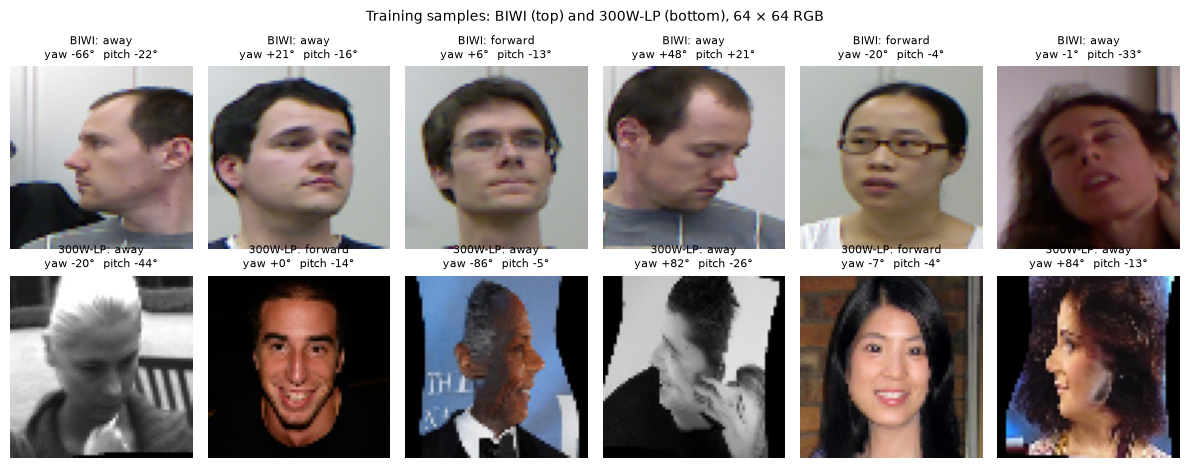

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(12, 4.8))
rng = np.random.default_rng(0)
for ax, i in zip(axes.flat, np.concatenate([rng.choice(idx["train"], 6, replace=False), rng.choice(idx["300wlp"], 6, replace=False)])):
    ax.imshow(images[i]); ax.axis("off")
    ax.set_title(f"{'BIWI' if i < nb else '300W-LP'}: {CLASSES[y[i]]}\nyaw {yaw[i]:+.0f}°  pitch {pitch[i]:+.0f}°", fontsize=8)
plt.suptitle("Training samples: BIWI (top) and 300W-LP (bottom), 64 × 64 RGB", fontsize=10)
plt.tight_layout(); plt.savefig(FIG / "samples.png", dpi=200); plt.show()

## 4. Preprocessing, metrics and the three model changes
Preprocessing is the same as Milestone 2 (scale to 0–1, ImageNet mean/std). The baseline enlarges 64 → 224; the small-input model skips this.

**Errors:** every wrong prediction is either *accepted* (head between 17.5° and 22.5°) or *real* (everything else).

In [5]:
X = torch.from_numpy(images).to(device)                   # uint8 on the GPU, preprocessed batch by batch
Y = torch.from_numpy(y).to(device)
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def augment(x):
    # Only used by the reference run in section 10 (augmentation is NOT one of our improvements).
    # Random left-right mirror (50%) and random brightness / contrast between 0.8 and 1.2.
    flip = torch.rand(len(x), device=x.device) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    contrast = torch.empty(len(x), 1, 1, 1, device=x.device).uniform_(0.8, 1.2)
    brightness = torch.empty(len(x), 1, 1, 1, device=x.device).uniform_(0.8, 1.2)
    mean = x.mean((1, 2, 3), keepdim=True)
    return (((x - mean) * contrast + mean) * brightness).clamp(0, 1)

def preprocess(batch_uint8, size, aug=False):
    x = batch_uint8.permute(0, 3, 1, 2).float() / 255.0
    if aug:
        x = augment(x)
    if size != x.shape[-1]:
        x = F.interpolate(x, size=size, mode="bilinear", align_corners=False)
    return (x - MEAN) / STD

def scores(true, pred, d):
    # macro-F1 and accuracy as in Milestone 2, plus the accepted / real split of the errors
    wrong, band = pred != true, np.abs(d) <= G
    return dict(macro_f1=f1_score(true, pred, average="macro"), accuracy=1 - wrong.mean(),
                errors=int(wrong.sum()), accepted_errors=int((wrong & band).sum()), real_errors=int((wrong & ~band).sum()),
                forward_called_away=int((wrong & ~band & (true == 1)).sum()), away_called_forward=int((wrong & ~band & (true == 0)).sum()))

class SE(nn.Module):
    # Squeeze-and-Excitation: average each channel, a tiny 2-layer network gives every channel a weight in (0, 2).
    # The last layer starts at zero, so every weight starts at exactly 1 and the pretrained network is unchanged at the start.
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.fc1, self.fc2 = nn.Linear(channels, channels // reduction), nn.Linear(channels // reduction, channels)
        nn.init.zeros_(self.fc2.weight); nn.init.zeros_(self.fc2.bias)
    def forward(self, x):
        w = 2 * torch.sigmoid(self.fc2(F.relu(self.fc1(x.mean((2, 3))))))
        return x * w[:, :, None, None]

def build_model(small_input, se, **_):
    m = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)     # same pretrained ResNet-18 in every experiment
    if small_input:                                          # A: read the 64x64 crop at full resolution
        m.conv1.stride = (1, 1)
        m.maxpool = nn.Identity()
    se_blocks = []
    if se:                                                   # C: SE block at the end of each residual branch
        for layer in (m.layer1, m.layer2, m.layer3, m.layer4):
            for block in layer:
                block.bn2 = nn.Sequential(block.bn2, SE(block.bn2.num_features))
                se_blocks.append(block.bn2[1])
    m.fc = nn.Linear(m.fc.in_features, 2)
    return m.to(device), se_blocks

for name, opts in EXPERIMENTS.items():
    m, se_blocks = build_model(**opts)
    size = 64 if opts["small_input"] else CFG["input_size"]
    with torch.no_grad():
        feat = nn.Sequential(*list(m.children())[:-2])(preprocess(X[:1], size))
    print(f"{name:18} input {size}x{size} -> last feature map {tuple(feat.shape[1:])}, "
          f"{sum(p.numel() for p in m.parameters()):,} parameters ({len(se_blocks)} SE blocks)")
del m

Baseline (MS2)     input 224x224 -> last feature map (512, 7, 7), 11,177,538 parameters (0 SE blocks)
A: Small input     input 64x64 -> last feature map (512, 8, 8), 11,177,538 parameters (0 SE blocks)


B: + 300W-LP       input 224x224 -> last feature map (512, 7, 7), 11,177,538 parameters (0 SE blocks)


C: SE attention    input 224x224 -> last feature map (512, 7, 7), 11,266,618 parameters (8 SE blocks)
A + B              input 64x64 -> last feature map (512, 8, 8), 11,177,538 parameters (0 SE blocks)


A + B + C          input 64x64 -> last feature map (512, 8, 8), 11,266,618 parameters (8 SE blocks)


## 5. Training
`run()` is the Milestone 2 training loop: stage 1 trains only the new layers, stage 2 also fine-tunes `layer4`.
The best epoch on the validation people is kept; the test people are used once, at the end.
Every finished run is saved to `ms3_runs.json`, so an interrupted session can continue where it stopped.

In [6]:
RUNS_FILE = Path("ms3_runs.json")
runs = json.loads(RUNS_FILE.read_text()) if RUNS_FILE.exists() else {}
use_amp = device.type == "cuda"

def run(name, seed, opts):
    cfg = {**CFG, **opts.get("cfg", {})}                     # section 10 only: changed hyperparameters
    finetune = opts.get("finetune", ["layer4"])              # layers trained in stage 2 (layer4, as in Milestone 2)
    aug = opts.get("augment", False)                         # section 10 only
    torch.manual_seed(seed); np.random.seed(seed)
    model, se_blocks = build_model(**opts)
    size = 64 if opts["small_input"] else CFG["input_size"]
    train_ids = np.concatenate([idx["train"], idx["300wlp"]]) if opts["extra_300wlp"] else idx["train"]
    n = np.bincount(y[train_ids], minlength=2)
    criterion = nn.CrossEntropyLoss(weight=torch.tensor(len(train_ids) / (2 * n), dtype=torch.float32, device=device))
    scaler = torch.amp.GradScaler(enabled=use_amp)
    gen = torch.Generator().manual_seed(seed)

    @torch.no_grad()
    def predict(ids_np):
        model.eval()
        ids = torch.from_numpy(ids_np).to(device)
        logits = []
        for b in ids.split(256):
            with torch.autocast(device.type, enabled=use_amp):
                logits.append(model(preprocess(X[b], size)).float())
        logits = torch.cat(logits)
        return criterion(logits, Y[ids]).item(), logits.argmax(1).cpu().numpy()

    history, best, t0 = [], dict(f1=-1.0), time.time()
    for stage in (1, 2):
        for p in model.parameters():
            p.requires_grad = False
        trainable = [model.fc] + se_blocks + ([getattr(model, l) for l in finetune] if stage == 2 else [])
        for m in trainable:
            for p in m.parameters():
                p.requires_grad = True
        optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=cfg[f"stage{stage}_lr"])
        for epoch in range(1, cfg[f"stage{stage}_epochs"] + 1):
            model.eval()                                     # frozen layers keep their BatchNorm statistics
            for m in trainable:
                m.train()
            ids = torch.from_numpy(train_ids)[torch.randperm(len(train_ids), generator=gen)].to(device)
            loss_sum, preds = 0.0, []
            for b in ids.split(cfg["batch_size"]):
                with torch.autocast(device.type, enabled=use_amp):
                    out = model(preprocess(X[b], size, aug)); loss = criterion(out, Y[b])
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
                loss_sum += loss.item() * len(b); preds.append(out.argmax(1))
            tr_f1 = f1_score(Y[ids].cpu().numpy(), torch.cat(preds).cpu().numpy(), average="macro")
            va_loss, va_pred = predict(idx["val"])
            va_f1 = f1_score(y[idx["val"]], va_pred, average="macro")
            history.append(dict(stage=stage, epoch=epoch, train_loss=loss_sum / len(ids), train_f1=tr_f1, val_loss=va_loss, val_f1=va_f1))
            flag = ""
            if va_f1 > best["f1"]:
                best = dict(f1=va_f1, epoch=len(history), state=copy.deepcopy(model.state_dict())); flag = "  <- best"
            print(f"  [{name} | seed {seed}] stage {stage} epoch {epoch:2d} | train loss {loss_sum / len(ids):.3f} F1 {tr_f1:.3f} "
                  f"| val loss {va_loss:.3f} F1 {va_f1:.3f}{flag}")
    minutes = (time.time() - t0) / 60
    model.load_state_dict(best["state"])
    torch.save(best["state"], CKPT / f"{re.sub(r'[^A-Za-z0-9+]+', '_', name).strip('_')}_seed{seed}.pt")
    out = dict(experiment=name, seed=seed, options=opts, train_images=len(train_ids), class_weights=criterion.weight.tolist(),
               minutes=round(minutes, 2), best_epoch=best["epoch"], history=history)
    for s in ("train", "val", "test"):
        _, pred = predict(idx[s])
        out[s] = scores(y[idx[s]], pred, dist[idx[s]])
    out["test_pred"] = pred.tolist()
    return out

def run_all(experiments):
    for name, opts in experiments.items():
        for seed in CFG["seeds"]:
            key = f"{name} | seed {seed}"
            if key in runs:
                print(f"{key}: already done (loaded from {RUNS_FILE})"); continue
            print(f"=== {key} ===")
            runs[key] = run(name, seed, opts)
            t = runs[key]["test"]
            print(f"=== {key}: best epoch {runs[key]['best_epoch']}, {runs[key]['minutes']:.1f} min | TEST macro-F1 {t['macro_f1']:.3f}  "
                  f"accuracy {t['accuracy']:.1%}  errors {t['errors']} = {t['accepted_errors']} accepted + {t['real_errors']} real\n")
            RUNS_FILE.write_text(json.dumps(runs, indent=1))

run_all(EXPERIMENTS)

Baseline (MS2) | seed 42: already done (loaded from ms3_runs.json)
Baseline (MS2) | seed 43: already done (loaded from ms3_runs.json)
Baseline (MS2) | seed 44: already done (loaded from ms3_runs.json)
A: Small input | seed 42: already done (loaded from ms3_runs.json)
A: Small input | seed 43: already done (loaded from ms3_runs.json)
A: Small input | seed 44: already done (loaded from ms3_runs.json)
B: + 300W-LP | seed 42: already done (loaded from ms3_runs.json)
B: + 300W-LP | seed 43: already done (loaded from ms3_runs.json)
B: + 300W-LP | seed 44: already done (loaded from ms3_runs.json)
C: SE attention | seed 42: already done (loaded from ms3_runs.json)
C: SE attention | seed 43: already done (loaded from ms3_runs.json)
C: SE attention | seed 44: already done (loaded from ms3_runs.json)
A + B | seed 42: already done (loaded from ms3_runs.json)
A + B | seed 43: already done (loaded from ms3_runs.json)
A + B | seed 44: already done (loaded from ms3_runs.json)
A + B + C | seed 42: alre

## 6. Results: every experiment, 3 seeds each
Mean ± standard deviation over the 3 seeds. **Gap** = train macro-F1 − validation macro-F1 (how much the model memorises the training people).

In [7]:
def agg(name, split, metric):
    v = np.array([runs[f"{name} | seed {s}"][split][metric] for s in CFG["seeds"]], dtype=float)
    return v.mean(), v.std()

def results_table(experiments):
    table = {}
    print(f"{'experiment':30} {'macro-F1':>14} {'accuracy':>14} {'all errors':>10} {'accepted':>9} {'REAL':>9} {'real %':>7}"
          f" {'val macro-F1':>14} {'gap':>13}")
    for name in experiments:
        gaps = np.array([runs[f"{name} | seed {s}"]["train"]["macro_f1"] - runs[f"{name} | seed {s}"]["val"]["macro_f1"] for s in CFG["seeds"]])
        row = {m: agg(name, "test", m) for m in ("macro_f1", "accuracy", "errors", "accepted_errors", "real_errors")}
        row["val_macro_f1"], row["gap"] = agg(name, "val", "macro_f1"), (gaps.mean(), gaps.std())
        table[name] = row
        print(f"{name:30} {row['macro_f1'][0]:>7.3f} ± {row['macro_f1'][1]:.3f} {row['accuracy'][0]:>7.1%} ± {row['accuracy'][1]:.1%}"
              f" {row['errors'][0]:>10.0f} {row['accepted_errors'][0]:>9.0f} {row['real_errors'][0]:>5.0f} ± {row['real_errors'][1]:<3.0f}"
              f"{row['real_errors'][0] / len(idx['test']):>6.1%} {row['val_macro_f1'][0]:>7.3f} ± {row['val_macro_f1'][1]:.3f}"
              f" {row['gap'][0]:>6.3f} ± {row['gap'][1]:.3f}")
    return table

print(f"Test set: {len(idx['test'])} images of 4 unseen people. Mean ± std over seeds {CFG['seeds']}. Errors are counts.\n")
table = results_table(EXPERIMENTS)
print("\nEvery single run (test set):")
for key, r in runs.items():
    if r["experiment"] in EXPERIMENTS:
        t = r["test"]
        print(f"  {key:28} macro-F1 {t['macro_f1']:.3f}  accuracy {t['accuracy']:.1%}  errors {t['errors']:3d} = {t['accepted_errors']:3d} accepted"
              f" + {t['real_errors']:3d} real  (real: {t['forward_called_away']} forward called away, {t['away_called_forward']} away called forward)")

Test set: 2029 images of 4 unseen people. Mean ± std over seeds [42, 43, 44]. Errors are counts.

experiment                           macro-F1       accuracy all errors  accepted      REAL  real %   val macro-F1           gap
Baseline (MS2)                   0.894 ± 0.021   89.7% ± 2.0%        209       110    99 ± 34   4.9%   0.872 ± 0.013  0.117 ± 0.022
A: Small input                   0.889 ± 0.011   89.4% ± 0.9%        215       111   104 ± 23   5.1%   0.922 ± 0.002  0.073 ± 0.003
B: + 300W-LP                     0.888 ± 0.013   89.1% ± 1.3%        222       119   103 ± 27   5.1%   0.945 ± 0.002  0.020 ± 0.023
C: SE attention                  0.887 ± 0.015   88.9% ± 1.5%        226       112   114 ± 30   5.6%   0.899 ± 0.016  0.058 ± 0.024
A + B                            0.908 ± 0.005   91.0% ± 0.5%        182       106    76 ± 6    3.7%   0.935 ± 0.009  0.051 ± 0.009
A + B + C                        0.899 ± 0.005   90.1% ± 0.6%        200       117    83 ± 13   4.1%   0.944 ± 0.

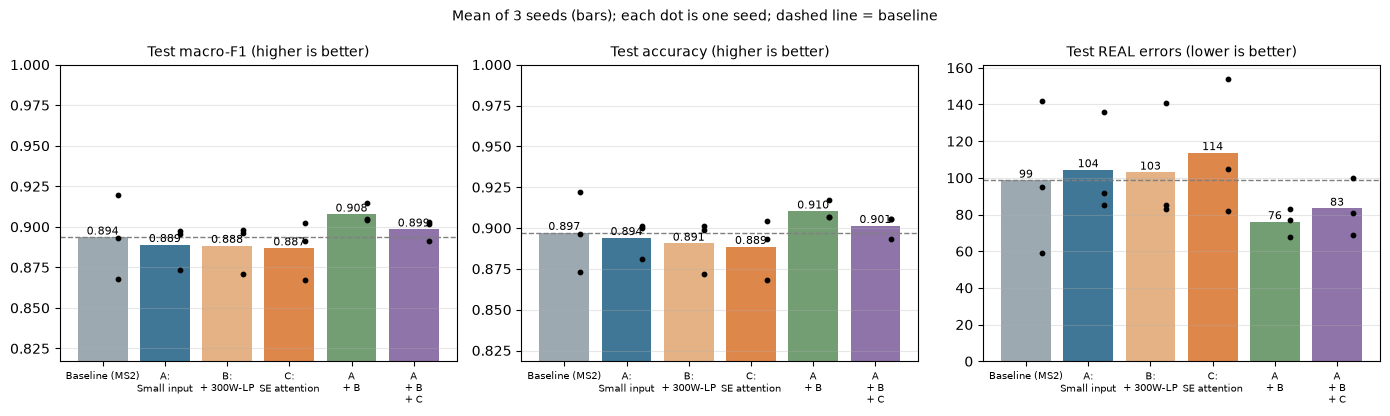

In [8]:
names = list(EXPERIMENTS)
colors = ["#8C9AA3"] + ["#1F5F84", "#E0A56E", "#D9722B", "#5B8C5A", "#7A5C99", "#B5524C", "#3E7C7C"][:len(names) - 1]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (metric, title) in zip(axes, (("macro_f1", "Test macro-F1 (higher is better)"), ("accuracy", "Test accuracy (higher is better)"),
                                      ("real_errors", "Test REAL errors (lower is better)"))):
    for i, (name, c) in enumerate(zip(names, colors)):
        vals = [runs[f"{name} | seed {s}"]["test"][metric] for s in CFG["seeds"]]
        ax.bar(i, np.mean(vals), color=c, alpha=0.85)
        ax.scatter([i + 0.25] * len(vals), vals, color="black", s=10, zorder=3)
        ax.text(i, np.mean(vals), f"{np.mean(vals):.3f}" if metric != "real_errors" else f"{np.mean(vals):.0f}",
                ha="center", va="bottom", fontsize=8)
    ax.axhline(np.mean([runs[f"{names[0]} | seed {s}"]["test"][metric] for s in CFG["seeds"]]), color="gray", ls="--", lw=1)
    ax.set_xticks(range(len(names)), [n.replace(": ", ":\n").replace(" + ", "\n+ ") for n in names], fontsize=7)
    if metric != "real_errors":
        lo = min(runs[k]["test"][metric] for k in runs if runs[k]["experiment"] in EXPERIMENTS)
        ax.set_ylim(max(0, lo - 0.05), 1.0)
    ax.set_title(title, fontsize=10); ax.grid(axis="y", alpha=0.3)
plt.suptitle("Mean of 3 seeds (bars); each dot is one seed; dashed line = baseline", fontsize=10)
plt.tight_layout(); plt.savefig(FIG / "results_bars.png", dpi=200); plt.show()

## 7. Training curves (validation macro-F1 and train–validation gap)
One line per seed. The dashed line marks the start of stage 2.

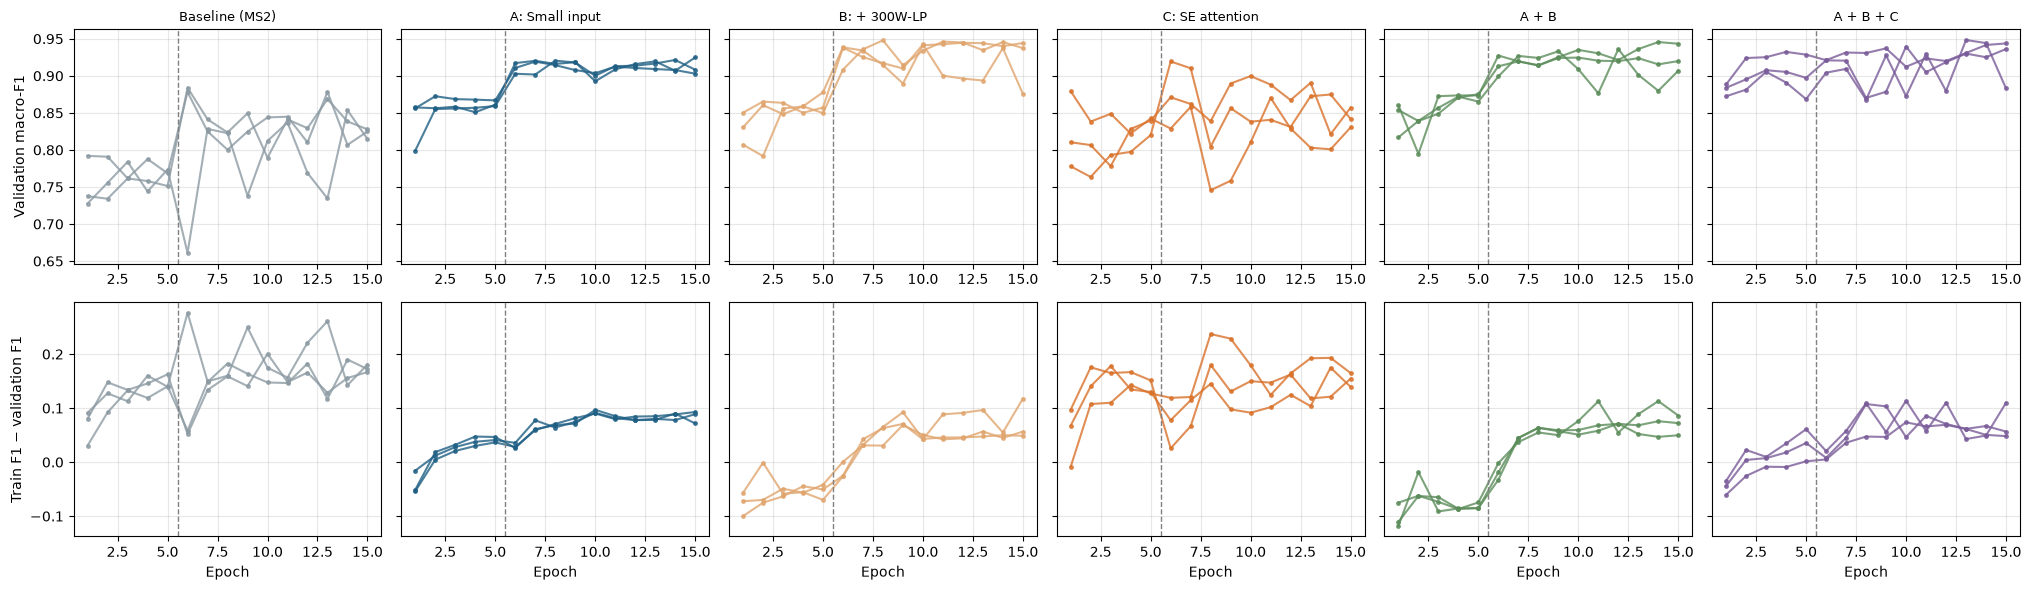

In [9]:
fig, axes = plt.subplots(2, len(names), figsize=(3.4 * len(names), 6), sharey="row")
for j, (name, c) in enumerate(zip(names, colors)):
    for s in CFG["seeds"]:
        h = runs[f"{name} | seed {s}"]["history"]
        ep = np.arange(1, len(h) + 1)
        axes[0, j].plot(ep, [e["val_f1"] for e in h], "o-", ms=2.5, color=c, alpha=0.8)
        axes[1, j].plot(ep, [e["train_f1"] - e["val_f1"] for e in h], "o-", ms=2.5, color=c, alpha=0.8)
    for ax in axes[:, j]:
        ax.axvline(CFG["stage1_epochs"] + 0.5, color="gray", ls="--", lw=1); ax.grid(alpha=0.3)
    axes[0, j].set_title(name, fontsize=9); axes[1, j].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Validation macro-F1"); axes[1, 0].set_ylabel("Train F1 − validation F1")
plt.tight_layout(); plt.savefig(FIG / "training_curves.png", dpi=200); plt.show()

## 8. Where are the errors now?
Test error rate by distance from the 20° line, averaged over the 3 seeds: baseline vs. every improvement.

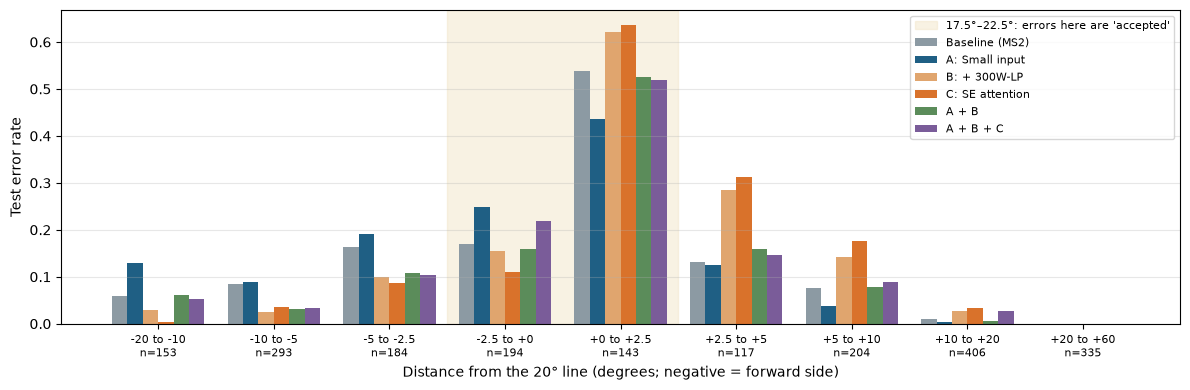

In [10]:
ti = idx["test"]
edges = np.array([-20, -10, -5, -2.5, 0, 2.5, 5, 10, 20, 60])
labels = [f"{lo:+g} to {hi:+g}" for lo, hi in zip(edges[:-1], edges[1:])]
fig, ax = plt.subplots(figsize=(12, 4))
w = 0.8 / len(names)
for k, (name, c) in enumerate(zip(names, colors)):
    rates = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (dist[ti] >= lo) & (dist[ti] < hi)
        rates.append(np.mean([(np.array(runs[f"{name} | seed {s}"]["test_pred"])[m] != y[ti][m]).mean() for s in CFG["seeds"]]))
    ax.bar(np.arange(len(rates)) + k * w - 0.4 + w / 2, rates, w, color=c, label=name)
counts = [int(((dist[ti] >= lo) & (dist[ti] < hi)).sum()) for lo, hi in zip(edges[:-1], edges[1:])]
ax.set_xticks(range(len(labels)), [f"{l}\nn={n}" for l, n in zip(labels, counts)], fontsize=8)
ax.axvspan(2.5, 4.5, color="#F2E6C9", alpha=0.5, zorder=0, label="17.5°–22.5°: errors here are 'accepted'")
ax.set_xlabel("Distance from the 20° line (degrees; negative = forward side)"); ax.set_ylabel("Test error rate")
ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig(FIG / "error_by_distance.png", dpi=200); plt.show()

## 9. Save the summary

In [11]:
best_name = max(names, key=lambda n: table[n]["macro_f1"][0])
best_seed = max(CFG["seeds"], key=lambda s: runs[f"{best_name} | seed {s}"]["val"]["macro_f1"])   # chosen on validation
print(f"Best experiment (mean test macro-F1): {best_name}")
print(f"Checkpoint for the webcam demo (best validation F1 among its seeds): seed {best_seed}")
summary = dict(config=CFG, experiments=EXPERIMENTS, people=people,
               device=str(torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu"), torch=torch.__version__,
               counts={s: dict(images=len(idx[s]), forward=int(y[idx[s]].sum())) for s in ("train", "300wlp", "val", "test")},
               table={n: {k: dict(mean=v[0], std=v[1]) for k, v in row.items()} for n, row in table.items()},
               best=dict(experiment=best_name, seed=best_seed))
Path("ms3_results.json").write_text(json.dumps(summary, indent=2))

Best experiment (mean test macro-F1): A + B
Checkpoint for the webcam demo (best validation F1 among its seeds): seed 44


6078

## 10. For reference only: augmentation and hyperparameter tuning
The Milestone 3 rules say these do **not** count as improvements. We run them only to see how much they would change the baseline,
so that our improvement (A + B) can be compared with them. Everything else is the same as the baseline.

In [12]:
REFERENCE = {
    "Ref: augmentation":            dict(small_input=False, extra_300wlp=False, se=False, augment=True),   # mirror + brightness/contrast
    "Ref: stage-2 lr 3e-4":         dict(small_input=False, extra_300wlp=False, se=False, cfg=dict(stage2_lr=3e-4)),
    "Ref: stage-2 lr 3e-5":         dict(small_input=False, extra_300wlp=False, se=False, cfg=dict(stage2_lr=3e-5)),
    "Ref: batch size 32":           dict(small_input=False, extra_300wlp=False, se=False, cfg=dict(batch_size=32)),
    "Ref: 20 stage-2 epochs":       dict(small_input=False, extra_300wlp=False, se=False, cfg=dict(stage2_epochs=20)),
    "Ref: fine-tune layer3+layer4": dict(small_input=False, extra_300wlp=False, se=False, finetune=["layer3", "layer4"]),
    "Ref: A + B + augmentation":    dict(small_input=True,  extra_300wlp=True,  se=False, augment=True),
}
run_all(REFERENCE)
print()
ref_table = results_table(["Baseline (MS2)", "A + B"] + list(REFERENCE))
summary["reference_table"] = {n: {k: dict(mean=v[0], std=v[1]) for k, v in row.items()} for n, row in ref_table.items()}
Path("ms3_results.json").write_text(json.dumps(summary, indent=2))

Ref: augmentation | seed 42: already done (loaded from ms3_runs.json)
Ref: augmentation | seed 43: already done (loaded from ms3_runs.json)
Ref: augmentation | seed 44: already done (loaded from ms3_runs.json)
Ref: stage-2 lr 3e-4 | seed 42: already done (loaded from ms3_runs.json)
Ref: stage-2 lr 3e-4 | seed 43: already done (loaded from ms3_runs.json)
Ref: stage-2 lr 3e-4 | seed 44: already done (loaded from ms3_runs.json)
Ref: stage-2 lr 3e-5 | seed 42: already done (loaded from ms3_runs.json)
Ref: stage-2 lr 3e-5 | seed 43: already done (loaded from ms3_runs.json)
Ref: stage-2 lr 3e-5 | seed 44: already done (loaded from ms3_runs.json)
Ref: batch size 32 | seed 42: already done (loaded from ms3_runs.json)
Ref: batch size 32 | seed 43: already done (loaded from ms3_runs.json)
Ref: batch size 32 | seed 44: already done (loaded from ms3_runs.json)
Ref: 20 stage-2 epochs | seed 42: already done (loaded from ms3_runs.json)
Ref: 20 stage-2 epochs | seed 43: already done (loaded from ms3_

12647